# ¿De qué parte del cielo llegan las explosiones más violentas del universo?

**Categoría: EDA (análisis exploratorio de datos). Corte del catálogo: 28 de octubre de 2026.**

Me pregunto con qué frecuencia detecta Fermi estallidos de rayos gamma y si sus posiciones se acumulan en una región del cielo. Analizo detecciones observadas por el monitor GBM de NASA. No genero predicciones propias.

## Ruta de lectura y glosario

Primero documento y limpio el catálogo; después cuento detecciones, dibujo su distribución y compruebo si las diferencias visibles superan lo esperable por azar.

- **Estallido de rayos gamma:** fogonazo de radiación muy energética que suele durar desde fracciones de segundo hasta minutos.
- **GBM:** monitor de estallidos de rayos gamma del telescopio espacial Fermi.
- **Coordenadas galácticas:** una forma de situar objetos usando el plano de la Vía Láctea como referencia.
- **Distribución uniforme:** cada zona de igual superficie del cielo tiene la misma probabilidad de recibir una detección.
- **Isotropía:** ausencia de una dirección privilegiada en la distribución observada.

## 1. Origen y unidad de observación

Descargo el catálogo `FERMIGBRST` del archivo HEASARC de NASA mediante su servicio TAP. Cada fila representa un aviso de Fermi clasificado como estallido de rayos gamma, no cualquier señal que activa el instrumento. Conservo la respuesta original en XML y una copia tabular en CSV.

El catálogo se actualiza continuamente. Por eso excluyo 2008, que empieza con el lanzamiento en julio, y 2026, todavía incompleto en la fecha de corte, cuando comparo años completos. Para estudiar el cielo sí utilizo todas las posiciones disponibles: aumentar el tamaño de la muestra ayuda, pero no elimina posibles sesgos del instrumento.

In [1]:
# importo las herramientas y fijo el estilo de los gráficos
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

color_principal = "#446ddf"
ruta_raiz = Path.cwd()
plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.max_columns = 20

In [2]:
# cargo la copia tabular y convierto la fecha sin depender del idioma del sistema
catalogo = pd.read_csv(ruta_raiz / "fermi_gbm_estallidos.csv")
catalogo["fecha"] = pd.to_datetime(catalogo["fecha"], utc=True)
catalogo["anio"] = catalogo["fecha"].dt.year

resumen_calidad = pd.Series({
    "filas": len(catalogo),
    "primera_deteccion": catalogo["fecha"].min().date().isoformat(),
    "ultima_deteccion": catalogo["fecha"].max().date().isoformat(),
    "coordenadas_ausentes": catalogo[["ra_deg", "dec_deg"]].isna().any(axis=1).sum(),
    "duraciones_ausentes": catalogo["t90_s"].isna().sum(),
})
resumen_calidad

filas                         4408
primera_deteccion       2008-07-14
ultima_deteccion        2026-10-29
coordenadas_ausentes             0
duraciones_ausentes              1
dtype: object

## 2. ¿Cuántos fogonazos detecta Fermi?

Cuento únicamente años naturales completos, de 2009 a 2025. Una detección no equivale a todos los estallidos que suceden en el universo: Fermi no observa siempre todo el cielo y solo registra señales que superan sus condiciones de detección.

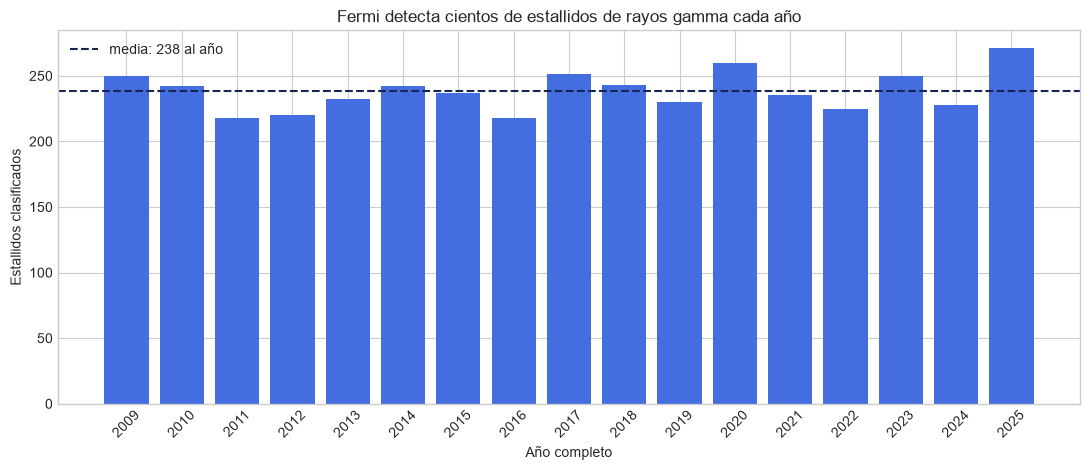

count     17.0
mean     238.4
std       15.0
min      218.0
25%      228.0
50%      237.0
75%      250.0
max      271.0
Name: detecciones, dtype: float64

In [3]:
# cuento los años completos para no comparar periodos de distinta duración
anios_completos = catalogo[catalogo["anio"].between(2009, 2025)]
conteo_anual = anios_completos.groupby("anio").size().rename("detecciones")

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(conteo_anual.index, conteo_anual.values, color=color_principal)
ax.axhline(conteo_anual.mean(), color="#172554", linestyle="--", label=f"media: {conteo_anual.mean():.0f} al año")
ax.set(title="Fermi detecta cientos de estallidos de rayos gamma cada año", xlabel="Año completo", ylabel="Estallidos clasificados")
ax.legend(frameon=False)
plt.xticks(conteo_anual.index, rotation=45)
plt.tight_layout()
plt.show()

conteo_anual.describe().round(1)

La serie permite medir la frecuencia observada, pero no interpreto sus altibajos como cambios del universo. También pueden intervenir la operación del satélite, la exposición del cielo, los umbrales y las revisiones del catálogo.

## 3. Un mapa del cielo entero

Convierto las coordenadas galácticas a una proyección ovalada. El centro marca la dirección al centro de la Vía Láctea y la línea horizontal representa su plano. Un mapa puede sugerir uniformidad, pero los puntos se solapan y la proyección distorsiona las áreas. Después hago una comprobación numérica.

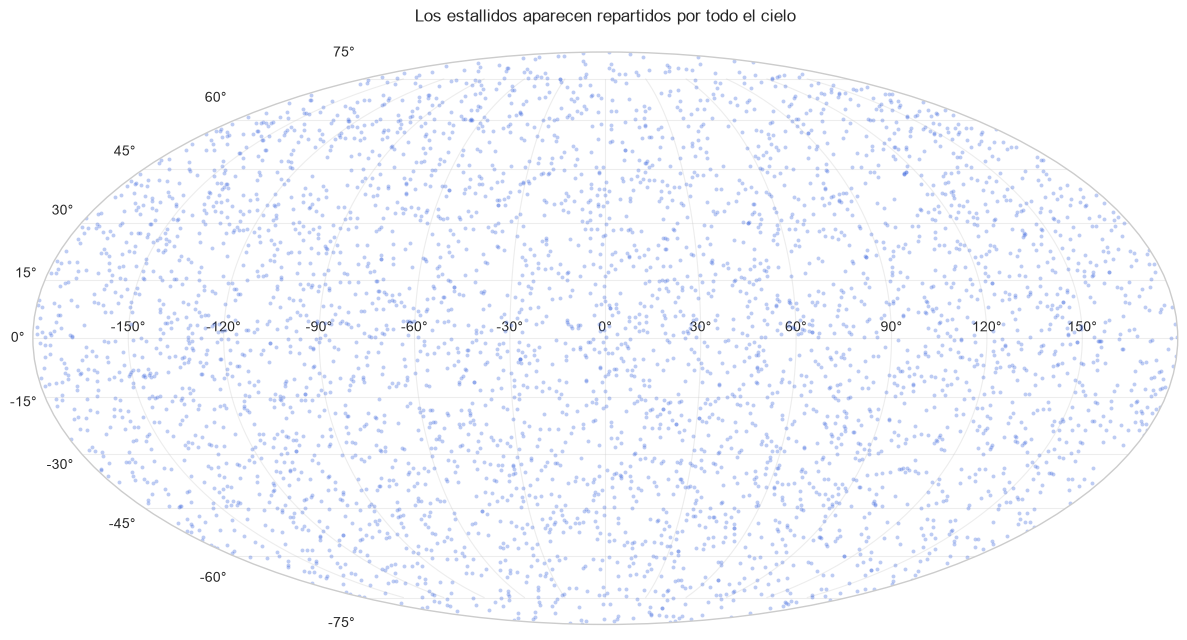

In [4]:
# preparo las longitudes entre -180 y 180 grados y las invierto por convención astronómica
longitud = ((catalogo["longitud_galactica_deg"] + 180) % 360) - 180
longitud_rad = np.deg2rad(-longitud)
latitud_rad = np.deg2rad(catalogo["latitud_galactica_deg"])

fig = plt.figure(figsize=(12, 6.5))
ax = fig.add_subplot(111, projection="mollweide")
ax.scatter(longitud_rad, latitud_rad, s=8, alpha=0.35, color=color_principal, linewidths=0)
ax.set_title("Los estallidos aparecen repartidos por todo el cielo", pad=22)
ax.grid(alpha=0.35)
plt.tight_layout()
plt.show()

## 4. Compruebo si la Vía Láctea deja una franja

Si la mayoría procediera de nuestra galaxia, esperaría una acumulación cerca de su plano, como una franja alrededor de latitud cero. Divido el cielo en diez bandas de **igual superficie**. Para conseguirlo no corto la latitud en grados iguales: utilizo el seno de la latitud, porque las zonas cercanas a los polos ocupan menos superficie.

Comparo el reparto observado con 20.000 cielos uniformes del mismo tamaño. La prueba resume la desigualdad de las diez bandas con una suma de desviaciones cuadráticas. No demuestra que cada estallido sea extragaláctico; comprueba si el conjunto muestra una concentración galáctica evidente.

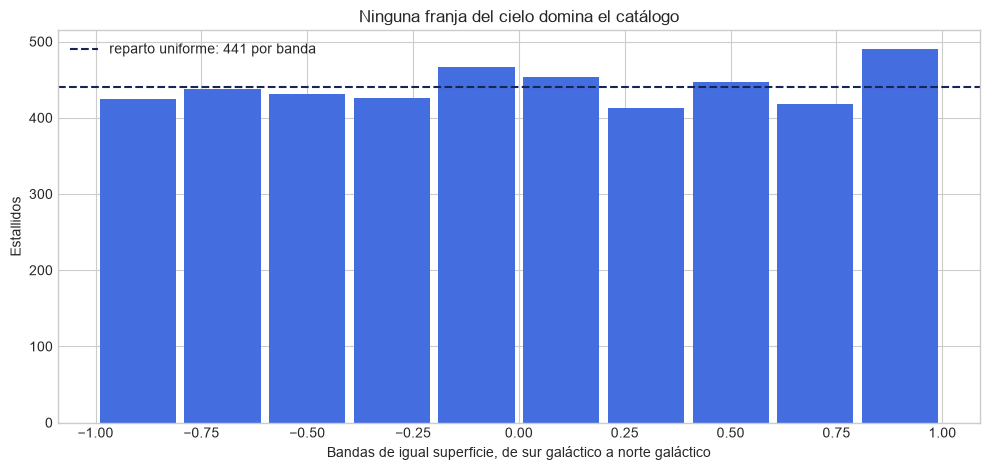

estadistico         11.6461
valor_p_simulado     0.2332
dtype: float64

In [5]:
# divido el seno de la latitud en bandas con la misma superficie celeste
semilla = 260310
generador = np.random.default_rng(semilla)
numero_bandas = 10
sin_latitud = np.sin(np.deg2rad(catalogo["latitud_galactica_deg"].dropna()))
bordes = np.linspace(-1, 1, numero_bandas + 1)
observado, _ = np.histogram(sin_latitud, bins=bordes)
esperado = len(sin_latitud) / numero_bandas
estadistico_observado = np.sum((observado - esperado) ** 2 / esperado)

# simulo cielos uniformes para no depender de una fórmula estadística oculta
simulados = generador.multinomial(len(sin_latitud), [1 / numero_bandas] * numero_bandas, size=20_000)
estadisticos_simulados = np.sum((simulados - esperado) ** 2 / esperado, axis=1)
valor_p = (np.count_nonzero(estadisticos_simulados >= estadistico_observado) + 1) / (len(simulados) + 1)

centros = (bordes[:-1] + bordes[1:]) / 2
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(centros, observado, width=0.18, color=color_principal)
ax.axhline(esperado, color="#172554", linestyle="--", label=f"reparto uniforme: {esperado:.0f} por banda")
ax.set(title="Ninguna franja del cielo domina el catálogo", xlabel="Bandas de igual superficie, de sur galáctico a norte galáctico", ylabel="Estallidos")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pd.Series({"estadistico": estadistico_observado, "valor_p_simulado": valor_p}).round(4)

Un valor p pequeño indicaría que un cielo uniforme rara vez produciría diferencias tan grandes entre bandas. Un valor alto significa que el reparto observado es compatible con fluctuaciones normales del azar. “Compatible” no significa “demostrado”: la sensibilidad de Fermi y la ocultación de la Tierra también modelan qué señales entran en el catálogo.

## 5. Dos hemisferios como comprobación sencilla

Repito la lectura sin bandas: cuento norte y sur galácticos. En una distribución uniforme espero aproximadamente la mitad en cada uno. Presento la diferencia junto a un intervalo típico obtenido con las mismas simulaciones.

In [6]:
# comparo los hemisferios y calculo el rango central del 95 % bajo uniformidad
norte = int((catalogo["latitud_galactica_deg"] > 0).sum())
sur = int((catalogo["latitud_galactica_deg"] < 0).sum())
total_hemisferios = norte + sur
simulacion_norte = generador.binomial(total_hemisferios, 0.5, size=20_000)
limite_inferior, limite_superior = np.quantile(simulacion_norte, [0.025, 0.975]).astype(int)

pd.Series({
    "norte_galactico": norte,
    "sur_galactico": sur,
    "porcentaje_norte": 100 * norte / total_hemisferios,
    "rango_esperable_norte_95_min": limite_inferior,
    "rango_esperable_norte_95_max": limite_superior,
}).round(1)

norte_galactico                 2222.0
sur_galactico                   2186.0
porcentaje_norte                  50.4
rango_esperable_norte_95_min    2140.0
rango_esperable_norte_95_max    2270.0
dtype: float64

## 6. Robustez y limitaciones

- El catálogo reúne detecciones de un instrumento, no todos los estallidos que ocurren.
- La Tierra bloquea parte del cielo y la sensibilidad depende de la orientación y del fondo.
- Las posiciones de GBM pueden tener incertidumbres de varios grados. Eso afecta a puntos individuales, pero es menos importante para diez bandas anchas.
- El catálogo puede revisar clasificaciones y parámetros; documento la fecha de corte.
- Una distribución uniforme en el cielo respalda un origen cosmológico para la población, pero este EDA no calcula distancias ni identifica la galaxia de cada evento.
- No confundo el número anual detectado con una tasa física del universo.

## 7. Conclusión

Fermi convierte una rareza aparente en una rutina científica: detecta cientos de estallidos de rayos gamma durante un año completo. Al dibujar todas las posiciones, no aparece una zona única del cielo que los monopolice. La comparación por bandas de igual superficie permite decidir si las diferencias son mayores de lo que produciría el azar.

La aportación de este análisis es unir frecuencia y geografía celeste en una lectura sencilla y comprobable. GRB 260310A puede ser excepcional por su evolución, pero forma parte de una lluvia de señales que llega desde todas las direcciones. El cielo no explota en un rincón concreto: nuestra posición está rodeada de un universo capaz de hacerlo.

## Fuentes y reproducción

- [NASA HEASARC: catálogo Fermi GBM Burst](https://heasarc.gsfc.nasa.gov/W3Browse/fermi/fermigbrst.html).
- [Fermi Science Support Center: datos y productos](https://fermi.gsfc.nasa.gov/ssc/data/access/).
- [Estudio de GRB 260310A](https://arxiv.org/abs/2605.23818).

Abro este notebook junto al CSV, instalo `requirements.txt` y ejecuto todas las celdas en orden. El CSV permite repetir el análisis sin conexión. `descargar_datos.py` documenta la consulta utilizada para renovar el catálogo.